# Don’t Stop ’til You Get Enough: Considerations of Audio Duration on Genre Classification in Deep Learning
**Daniel Bruning - 11/07/2026**

## Elevator Pitch

If you walk into a music store or browse for Michael Jackson online, how would you expect his music to be categorized? Under pop? Under R&B? Under local artists if you happened upon a record store in Gary, Indiana? Most artist and song genres appear intuitive if not obvious. Yet, depending on where you are, what you are familiar with, and who is doing the categorizing, our notions of what define a genre and what examples are true examples of a genre shift. Genre may function as a useful, marketable classification, yet the defining boundaries of what specific songs or artists they circumscribe is fluid and contested.

Now consider machine learning systems being tasked with classifying songs. Before a model can learn to classify music, someone must decide what genres exist, what songs belong to each category, and what characteristics distinguish one genre from another. These decisions define the data the model learns from and thus the predictions it makes in concluding where a song fits.

A common assumption in language model training is more data begets better model performance. If a few seconds of audio are useful then even more seconds should be better. Give it the full catalogue to learn from! If a model can identify a genre from a short excerpt then surely providing the full song should provide the best possible accuracy. Yet, the folks behind tuning machine learning systems frequently encounter diminishing returns in such pursuits. Additional data increases computational cost, storage requirements, and training time. Meanwhile, the resulting performance for all the additional resources and effort may become progressively smaller.

This project investigates whether such a point exists in music genre classification. By comparing performance across multiple architectures and clip lengths, this experiment asks a relatively straightforward question:

How much of a song does a model actually need before it can reliably recognize its genre?

If such a threshold exists, additional audio contributes little new information to the classification task beyond it. This experiment was conducted to look at how various deep learning architectures perform when carrying out music genre classification using audio clips of durations between 1 and 30 seconds. It assesses the models' performance, their sensitivity to duration, behaviour specific to each genre, computational efficiency, generalisation properties, and the kinds of errors they make.

## Reproducibility and Source Code

The complete implementation used throughout this project is maintained in the accompanying GitHub repository:

https://github.com/d-bruning/deep-learning-audio-classification

The repository contains the preprocessing pipeline, dataset partitioning procedures, spectrogram generation scripts, model implementations, experiment execution notebooks, analysis notebooks, and supporting configuration files used to generate the results presented here.

To keep this notebook focused on experimental methodology, results, and interpretation, detailed execution instructions are maintained within the repository documentation rather than duplicated here. The repository README provides step-by-step instructions for obtaining the GTZAN and FMA Small datasets, generating duration-specific excerpts, creating Mel spectrograms, executing the experimental runs, and reproducing the analytical outputs reported in this notebook.

This notebook therefore serves as a documented record of the experimental workflow and findings, while the repository serves as the primary reproducibility artifact for regenerating data, rerunning experiments, and reproducing analyses.

## Experimental Design

The project ultimately evolved into a three-stage investigation.

The first stage used the GTZAN dataset to explore whether the amount of available listening context influences music genre classification performance. Audio excerpts ranging from 1 second to 30 seconds were evaluated across multiple deep learning architectures. The goal was to determine whether longer excerpts consistently improved performance and whether those improvements differed across model families.

The second stage repeated the same duration experiment using the substantially larger FMA Small dataset. Rather than simply increasing the amount of training data, this phase served as a replication study. If duration effects observed in GTZAN reflected genuine properties of music classification, similar patterns should appear on a different dataset with different genres, artists, and recordings.

The final stage focused on MobileNetV2. After the comparative experiments identified MobileNetV2 as the strongest-performing architecture on FMA Small, a targeted refinement experiment was conducted to explore how a promising model responds to additional tuning and to demonstrate the full experimental workflow within this notebook.

Across all experiments, models were evaluated using accuracy, precision, recall, F1 score, balanced accuracy, Cohen's kappa, duration sensitivity, parameter efficiency, genre-specific performance, confusion patterns, and generalization behavior.

## The Datasets

The study intentionally uses two datasets. GTZAN provides a widely used benchmark for music genre classification, while FMA Small provides a larger and more diverse collection of recordings. Using both datasets allows findings to be evaluated for consistency rather than relying on a single benchmark.

### Free Music Archive (FMA) Dataset

This project utilizes the Free Music Archive (FMA) dataset developed by
Michaël Defferrard, Kirell Benzi, Pierre Vandergheynst, and Xavier
Bresson. The FMA dataset was created specifically to support research in
music information retrieval and music analysis. The FMA Small subset
contains 8,000 tracks distributed across 8 balanced genre categories.

The dataset is hosted by the Swiss Data Science Center (EPFL and ETHZ).
Metadata are distributed under the Creative Commons Attribution 4.0
International License (CC BY 4.0), while individual audio recordings are
distributed under licenses selected by their respective artists.

Source Dataset:
https://github.com/mdeff/fma

Citation:

Defferrard, M., Benzi, K., Vandergheynst, P., & Bresson, X. (2017).
FMA: A Dataset for Music Analysis. Proceedings of the 18th International
Society for Music Information Retrieval Conference (ISMIR).

https://arxiv.org/abs/1612.01840

### GTZAN
This project uses the GTZAN Music Genre Dataset, originally developed by
George Tzanetakis and Perry Cook (2002). The dataset contains 1,000
30-second audio excerpts spanning 10 musical genres and remains one of
the most widely used benchmarks for music genre recognition research.

Source Dataset:
https://www.kaggle.com/datasets/andradaolteanu/gtzan-dataset-music-genre-classification

Citation:
Tzanetakis, G., & Cook, P. (2002). Musical genre classification of audio
signals. IEEE Transactions on Speech and Audio Processing, 10(5), 293–302.

## Dataset Limitations

Both datasets represent curated genre taxonomies rather than objective musical truth. Genre labels are assigned by people and organizations, meaning category boundaries often overlap. A song classified as Pop might also be described as Rock, Electronic, Hip-Hop, or Folk depending on the cataloging system being used.

GTZAN additionally contains well-documented limitations, including potential recording duplicates, artist overlap, and labeling inconsistencies. FMA Small is larger and more diverse but introduces its own challenges through broader genre definitions and substantial overlap among musical styles. Consequently, results throughout this notebook are interpreted as comparative evaluations within the selected benchmark datasets rather than definitive estimates of real-world genre classification performance.

## Dataset Preparation Decisions

To ensure valid comparison across architectures, durations, and datasets, several design choices were standardized throughout the study.

A fixed song-level train, validation, and test split was created for each dataset and reused across all experimental conditions. This ensured performance differences could not be attributed to changes in dataset composition. All audio excerpts were converted to Mel spectrograms using a common preprocessing workflow. Multiple random seeds were used for every duration condition to reduce sensitivity to stochastic training behavior.

The central independent variable throughout the study was audio duration. By evaluating the same recordings at multiple lengths while holding all other characteristics constant, the experiments isolate how the amount of available listening context influences classification performance.

### Duration-Based Evaluation

The GTZAN and FMA recordings contain substantially more audio than may actually be necessary for genre recognition. If a model can correctly identify a song's genre from only a few seconds of listening, then processing the entire recording may provide little additional benefit while increasing storage requirements, preprocessing time, training cost, and model complexity.

To investigate this question, duration-specific excerpts of 1, 3, 5, 10, 15, 20, 25, and 30 seconds were generated from the same source recordings. Because every excerpt originated from the same song, the experiment could vary the amount of available listening context while holding other recording characteristics constant. This design allowed audio duration to function as the primary independent variable and enabled direct measurement of how additional listening time influences genre-classification performance.

### Center-Based Clip Extraction

To ensure duration comparisons sampled comparable portions of each recording, excerpts were extracted from the center of each song rather than from the beginning or end. For each target duration, the required number of audio samples was calculated and centered within the original recording. If a recording was shorter than the requested duration, the full recording was retained.

Using centered excerpts reduced the likelihood results would be driven by idiosyncratic properties of song introductions or endings. Many recordings contain fade-ins, fade-outs, silence, spoken introductions, applause, or other transitional segments near their boundaries. Extracting excerpts from the middle of a track increased the probability of each sample contained representative musical content while maintaining a consistent procedure across all durations and datasets.

This design choice was intended to improve comparability between duration conditions by ensuring 1-second, 3-second, and 30-second excerpts were derived from the same general region of the original recording rather than from different structural sections of the song.

### Spectrogram Representation

Neural networks cannot directly interpret an audio recording in the same way a human listener can. Before a model can learn from music, the audio signal must be transformed into a representation to capture the characteristics of the sound in a machine-readable format.

To accomplish this, all audio excerpts were converted into Mel spectrograms. A Mel spectrogram is a visual representation of sound to show how frequency content changes over time. Time is represented across the horizontal axis, frequency across the vertical axis, and color intensity indicates the strength of particular frequencies. This transformation converts an audio waveform into an image-like representation while preserving much of the temporal and spectral information to distinguish one musical genre from another.

Using a common spectrogram representation across all experiments ensured any differences in performance could be attributed primarily to model architecture and audio duration rather than differences in feature extraction methodology. Although the GTZAN dataset distribution included pre-generated spectrogram images, those images were not used in this study. Instead, all GTZAN and FMA Small spectrograms were regenerated using the same Mel-spectrogram pipeline and parameter settings. This decision ensured every experimental condition, regardless of dataset, duration, or architecture, was derived from a consistent preprocessing workflow and observed performance differences could not be attributed to differences in spectrogram generation procedures.

### Fixed Data Partitioning

A song-level partitioning strategy was employed to create training, validation, and test sets prior to model development. The resulting split file was reused for all architectures, durations, and experimental runs. This ensured every model was evaluated on identical observations and prevented variation in data partitioning to allow stronger comparisons across architectures or duration conditions.

### Multiple Random Seeds

Each experimental condition was repeated across multiple random seeds to reduce sensitivity to stochastic effects arising from parameter initialization, data shuffling, and optimization. Repeated trials enabled estimation of average performance and variability across runs, providing a more stable characterization of model behavior than any individual training instance. Aggregate statistics derived from these repeated experiments were subsequently used for comparative analysis and interpretation.

### Standardized Evaluation Framework

All architectures were evaluated using the same performance metrics, including accuracy, balanced accuracy, precision, recall, F1 score, top-2 accuracy, top-3 accuracy, and Cohen's kappa. Applying a consistent evaluation framework across models and duration conditions enabled direct comparison of performance trends and supported investigation of whether observed duration effects were specific to a given architecture or broadly consistent across different deep learning approaches.

## Model Selection
The selected architectures were not intended to identify a universally optimal music genre classifier. Instead, they were chosen to represent different approaches to learning from spectrogram representations.

The GTZAN study evaluated MLP, CNN, MobileNetV2, VGG, ShallowResNet, ResidualCNN, CRNN, and CapsNet in order to survey a broad collection of neural network families. These architectures span fully connected, convolutional, residual, recurrent, transfer-learning, and capsule-network designs.

The FMA Small replication study narrowed the architecture set to CNN, MobileNetV2, CRNN, and ViT. These models were selected because they represent distinct modeling philosophies: convolutional learning, transfer learning, temporal sequence modeling, and transformer-based attention. Reducing the architecture set allowed deeper investigation of duration effects while maintaining architectural diversity.

Finally, MobileNetV2 was selected for focused refinement because it emerged as the strongest overall performer in the FMA Small experiments. Rather than introducing an entirely new architecture, the refinement study investigates what can be learned by examining a successful model more closely.

## From Broad Comparisons to Focused Investigation

The experiments described in the previous sections were designed primarily as comparative studies. The goal was not to identify the single best architecture or maximize classification accuracy through extensive hyperparameter tuning. Instead, the objective was to investigate how audio duration influences music genre classification performance across different model families, datasets, and genres under reasonably consistent training conditions.

To support this objective, architectures were configured only to the point where they demonstrated stable learning behavior. Once satisfactory convergence was achieved, hyperparameters were largely held constant throughout the duration experiments. This approach helped ensure observed differences in performance could be attributed to architecture and clip length rather than extensive model-specific tuning.

The resulting experiments identified MobileNetV2 as an architecture of particular interest. Across the FMA Small study, MobileNetV2 achieved the highest overall classification accuracy, the strongest F1 score, the largest statistically significant duration gain, and the smallest generalization gap. At the same time, the model exhibited no observed overfitting across the evaluated experimental conditions.

These results naturally raise a follow-up question. If MobileNetV2 emerged as the strongest-performing architecture under a standardized experimental configuration, what happens when the focus shifts from broad comparison to targeted refinement?

The following experiment therefore narrows the scope considerably. Rather than evaluating multiple architectures across multiple durations, the notebook examines a single MobileNetV2 configuration using a representative duration condition and random seed. The purpose is not to establish a new benchmark or replace the primary experiments. Instead, the refinement serves as an example of how findings from an exploratory study can motivate a more focused investigation of a promising architecture.

The experiment also provides a complete demonstration of the project workflow, including dataset loading, model construction, training, evaluation, artifact generation, and result interpretation. While the full studies involved hundreds of completed experimental runs, the refinement example illustrates the underlying process without requiring the reader to reproduce the entire experimental campaign.

## Experimental Pipeline Demonstration

The GTZAN and FMA Small studies collectively required hundreds of individual training runs spanning multiple architectures, audio durations, and random seeds. Reproducing the entire experimental campaign within this notebook would be impractical and would obscure the underlying workflow responsible for generating the reported results.

Instead, this section presents a representative experiment using MobileNetV2. The architecture was selected because it emerged as the strongest overall performer in the FMA Small study, achieving the highest overall accuracy (0.508), the largest statistically significant duration gain (+5.8%), and the smallest observed generalization gap (0.074). The purpose of this demonstration is not to establish new experimental findings, but rather to illustrate the complete training and evaluation workflow used throughout the project.

To keep the demonstration computationally manageable while remaining representative of the larger study, a single experimental condition is evaluated:

| Setting | Value |
|----------|----------|
| Architecture | MobileNetV2 |
| Dataset | FMA Small |
| Duration | 15 seconds |
| Input Resolution | 224 × 224 |
| Learning Rate | 1e-5 |
| Random Seed | 42 |
| Evaluation Metrics | Accuracy, Precision, Recall, F1 Score |

This configuration represents a focused follow-on investigation rather than a new comparative study. All other aspects of the experimental framework remain consistent with the methodology used throughout the FMA Small investigation, allowing any observed changes to be attributed primarily to the revised MobileNetV2 training configuration.

## Imports

In [92]:
# =====================================================
# STANDARD LIBRARY STUFF
# =====================================================

from pathlib import Path
from datetime import datetime
import time

# =====================================================
# ADDITIONAL LIBRARIES
# =====================================================

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau
)

from tensorflow.keras.models import Model

from tensorflow.keras.layers import (
    Input,
    GlobalAveragePooling2D,
    Dense,
    Dropout
)

from tensorflow.keras.optimizers import Adam

from tensorflow.keras.applications import (
    MobileNetV2
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

### MobileNetV2 Model

In [93]:
# =====================================================
# MOBILENETV2 ARCHITECTURE
# =====================================================

from tensorflow.keras.models import Model

from tensorflow.keras.layers import (

    Input,

    GlobalAveragePooling2D,

    Dense,

    Dropout
)

from tensorflow.keras.optimizers import Adam

from tensorflow.keras.applications import (
    MobileNetV2
)

### Project Paths

In [94]:
# =====================================================
# PROJECT PATHS
# =====================================================

PROJECT_ROOT = Path.cwd()

DATA_DIR = (
    PROJECT_ROOT /
    "data" /
    "fma_small"
)

METADATA_DIR = (
    DATA_DIR /
    "metadata"
)

SPECTROGRAM_DIR = (
    DATA_DIR /
    "spectrograms"
)

FMA_SPLIT_FILE = (
    METADATA_DIR /
    "fma_song_splits.csv"
)

print(
    f"Dataset: {DATASET_NAME}"
)

print(
    f"Split File Exists: "
    f"{FMA_SPLIT_FILE.exists()}"
)

print(
    f"Spectrogram Directory Exists: "
    f"{SPECTROGRAM_DIR.exists()}"
)

Dataset: FMA Small
Split File Exists: True
Spectrogram Directory Exists: True


### Experiment Configuration

The objective of this demonstration is to illustrate the complete experimental workflow using a representative configuration from the broader FMA Small study. MobileNetV2 was selected because it achieved the highest overall classification performance, the strongest duration sensitivity, and the strongest generalization characteristics among the evaluated architectures. A 15-second excerpt and seed 42 were selected as representative experimental conditions. The learning rate was reduced from the original FMA configuration (1×10⁻⁴) to 1×10⁻⁵ as part of the follow-on refinement experiment.

In [95]:
# =====================================================
# EXPERIMENT CONFIGURATION
# =====================================================

DATASET_NAME = "FMA Small"

MODEL_NAME = "mobilenetv2"

SEED = 42

DURATION = "15s"

IMG_SIZE = (224, 224)

BATCH_SIZE = 32

EPOCHS = 30

LEARNING_RATE = 1e-5

NUM_CLASSES = 8

CLASS_NAMES = [

    "electronic",
    "experimental",
    "folk",
    "hip-hop",
    "instrumental",
    "international",
    "pop",
    "rock"
]

GENRE_TO_INT = {

    genre: idx

    for idx, genre

    in enumerate(CLASS_NAMES)
}

In [96]:
print(
    f"Dataset: {DATASET_NAME}"
)

print(
    f"Architecture: {MODEL_NAME}"
)

print(
    f"Duration: {DURATION}"
)

print(
    f"Seed: {SEED}"
)

print(
    f"Image Size: {IMG_SIZE}"
)

print(
    f"Learning Rate: {LEARNING_RATE}"
)

print(
    f"Classes: {NUM_CLASSES}"
)

Dataset: FMA Small
Architecture: mobilenetv2
Duration: 15s
Seed: 42
Image Size: (224, 224)
Learning Rate: 1e-05
Classes: 8


### Model Configuration: MobileNetV2

The FMA Small experiments identified MobileNetV2 as the strongest-performing architecture. Rather than introducing a new model family, the demonstration experiment revisits MobileNetV2 using a more conservative learning rate. This focused investigation illustrates how a promising architecture might be examined following completion of a broader comparative study while limiting the number of experimental variables introduced.

In [97]:
# =====================================================
# MOBILENETV2 MODEL
# =====================================================

from tensorflow.keras.models import Model

from tensorflow.keras.layers import (

    Input,

    GlobalAveragePooling2D,

    Dense,

    Dropout
)

from tensorflow.keras.optimizers import Adam

from tensorflow.keras.applications import (
    MobileNetV2
)


def build_mobilenetv2_refined(

    input_shape,

    num_classes,

    learning_rate=1e-5
):
    """
    Refined MobileNetV2 classifier used for the
    demonstration experiment.

    Changes relative to the original FMA study:

    1. Uses a reduced learning rate (1e-5)
       instead of 1e-4.

    2. Preserves the pretrained ImageNet
       feature extractor.

    The goal is not to establish a new benchmark,
    but to demonstrate how a promising architecture
    may be investigated further following the
    primary experimental results.
    """

    inputs = Input(
        shape=input_shape
    )

    backbone = MobileNetV2(

        include_top=False,

        weights="imagenet",

        input_tensor=inputs
    )

    # -----------------------------------------
    # Preserve pretrained feature extractor
    # -----------------------------------------

    backbone.trainable = False

    # -----------------------------------------
    # Classification Head
    # -----------------------------------------

    x = GlobalAveragePooling2D()(
        backbone.output
    )

    x = Dense(
        256,
        activation="relu"
    )(x)

    x = Dropout(
        0.5
    )(x)

    outputs = Dense(

        num_classes,

        activation="softmax"

    )(x)

    model = Model(

        inputs=inputs,

        outputs=outputs,

        name="mobilenetv2_refined"
    )

    model.compile(

        optimizer=Adam(
            learning_rate=learning_rate
        ),

        loss="sparse_categorical_crossentropy",

        metrics=[
            "accuracy"
        ]
    )

    return model

### Load Metadata

In [98]:
split_df = pd.read_csv(
    FMA_SPLIT_FILE
)

print(
    split_df["split"]
    .value_counts()
)

print()

print(
    split_df.groupby(
        ["split", "genre"]
    ).size()
)

split
train    5600
val      1200
test     1200
Name: count, dtype: int64

split  genre        
test   Electronic       150
       Experimental     150
       Folk             150
       Hip-Hop          150
       Instrumental     150
       International    150
       Pop              150
       Rock             150
train  Electronic       700
       Experimental     700
       Folk             700
       Hip-Hop          700
       Instrumental     700
       International    700
       Pop              700
       Rock             700
val    Electronic       150
       Experimental     150
       Folk             150
       Hip-Hop          150
       Instrumental     150
       International    150
       Pop              150
       Rock             150
dtype: int64


### Generate File List

In [99]:
# =====================================================
# BUILD FILE LISTS
# =====================================================

def build_file_lists(
    duration,
    split_name,
    split_df
):

    subset = split_df[
        split_df["split"]
        == split_name
    ]

    image_paths = []
    labels = []

    missing_count = 0

    for _, row in subset.iterrows():

        genre = (
            row["genre"]
            .strip()
            .lower()
        )

        image_path = (

            SPECTROGRAM_DIR

            / duration

            / genre

            / f"{row['track_id']}.png"
        )

        if image_path.exists():

            image_paths.append(
                str(image_path)
            )

            labels.append(
                GENRE_TO_INT[
                    genre
                ]
            )

        else:

            missing_count += 1

    print(
        f"{split_name}: "
        f"{len(image_paths)} images "
        f"({missing_count} missing)"
    )

    return (
        image_paths,
        labels
    )

### Validate File Discovery

In [100]:
train_paths, train_labels = (
    build_file_lists(
        DURATION,
        "train",
        split_df
    )
)

print(
    f"Training Examples: "
    f"{len(train_paths)}"
)

print(
    f"Unique Labels: "
    f"{len(set(train_labels))}"
)

print(
    f"First Spectrogram:\n"
    f"{train_paths[0]}"
)

train: 5598 images (2 missing)
Training Examples: 5598
Unique Labels: 8
First Spectrogram:
/Users/daniel.bruning/Desktop/audio-classification/data/fma_small/spectrograms/15s/folk/10992.png


### Build Tensorflow Dataset

In [101]:
# =====================================================
# IMAGE PARSING
# =====================================================

def parse_image(
    image_path,
    label
):

    label = tf.cast(
        label,
        tf.int32
    )

    image = tf.io.read_file(
        image_path
    )

    image = tf.image.decode_png(
        image,
        channels=3
    )

    image = tf.image.resize(
        image,
        IMG_SIZE
    )

    image = (
        tf.cast(
            image,
            tf.float32
        )
        / 255.0
    )

    return (
        image,
        label
    )


# =====================================================
# DATASET CONSTRUCTION
# =====================================================

def make_dataset(
    paths,
    labels,
    training=False
):

    ds = (
        tf.data.Dataset
        .from_tensor_slices(
            (
                paths,
                labels
            )
        )
    )

    ds = ds.map(
        parse_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    if training:

        ds = ds.shuffle(
            buffer_size=len(paths),
            reshuffle_each_iteration=True
        )

    ds = ds.batch(
        BATCH_SIZE
    )

    ds = ds.prefetch(
        tf.data.AUTOTUNE
    )

    return ds

### Create Training, Validation, and Test Datasets

In [102]:
train_files, train_labels = (
    build_file_lists(
        DURATION,
        "train",
        split_df
    )
)

val_files, val_labels = (
    build_file_lists(
        DURATION,
        "val",
        split_df
    )
)

test_files, test_labels = (
    build_file_lists(
        DURATION,
        "test",
        split_df
    )
)

train_ds = make_dataset(
    train_files,
    train_labels,
    training=True
)

val_ds = make_dataset(
    val_files,
    val_labels
)

test_ds = make_dataset(
    test_files,
    test_labels
)

print(train_ds)

print(
    f"\nTrain Samples: "
    f"{len(train_files)}"
)

print(
    f"Validation Samples: "
    f"{len(val_files)}"
)

print(
    f"Test Samples: "
    f"{len(test_files)}"
)

train: 5598 images (2 missing)
val: 1198 images (2 missing)
test: 1198 images (2 missing)
<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>

Train Samples: 5598
Validation Samples: 1198
Test Samples: 1198


### Validate Datasets
The dataset pipeline should successfully locate and load the expected spectrogram representations for the selected experimental condition. A total of 5,598 training samples, 1,198 validation samples, and 1,198 test samples were identified for the 15-second duration condition. All images were resized to 224 × 224 pixels to match the MobileNetV2 input requirements and normalized to the range [0,1] prior to training. A small number of missing spectrogram files were detected, consistent with the larger FMA Small experiments, but the overall dataset integrity remained intact.

In [103]:
for images, labels in train_ds.take(1):

    print(
        f"Images: {images.shape}"
    )

    print(
        f"Labels: {labels.shape}"
    )

    print(
        f"Pixel Range: "
        f"{images.numpy().min():.3f} "
        f"to "
        f"{images.numpy().max():.3f}"
    )

Images: (32, 224, 224, 3)
Labels: (32,)
Pixel Range: 0.000 to 0.997


2026-11-08 15:16:30.276875: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


### Build the Model

In [104]:
# =====================================================
# BUILD MODEL
# =====================================================

model = build_mobilenetv2_refined(

    input_shape=IMG_SIZE + (3,),

    num_classes=NUM_CLASSES,

    learning_rate=LEARNING_RATE
)

parameter_count = (
    model.count_params()
)

print(
    f"Model: {MODEL_NAME}"
)

print(
    f"Input Shape: "
    f"{IMG_SIZE + (3,)}"
)

print(
    f"Parameters: "
    f"{parameter_count:,}"
)

print(
    f"Learning Rate: "
    f"{LEARNING_RATE}"
)

print(
    f"Classes: "
    f"{NUM_CLASSES}"
)

/var/folders/qz/r6zcdhhj4y76lwkb5jxn730w0000gp/T/ipykernel_67585/4285425867.py:55: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  backbone = MobileNetV2(


Model: mobilenetv2
Input Shape: (224, 224, 3)
Parameters: 2,587,976
Learning Rate: 1e-05
Classes: 8


### Inspect Model

In [105]:
model.summary()

Model: "mobilenetv2_refined"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,587,976 (9.87 MB)

 Trainable params: 329,992 (1.26 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

### Trainable and Non-Trainable Parameters

In [106]:
trainable_params = np.sum(
    [
        np.prod(v.shape)
        for v in model.trainable_weights
    ]
)

non_trainable_params = np.sum(
    [
        np.prod(v.shape)
        for v in model.non_trainable_weights
    ]
)

print(
    f"Trainable Parameters: "
    f"{trainable_params:,}"
)

print(
    f"Non-Trainable Parameters: "
    f"{non_trainable_params:,}"
)

Trainable Parameters: 329,992
Non-Trainable Parameters: 2,257,984


The MobileNetV2 architecture contains 2,587,976 total parameters, of which 329,992 are trainable and 2,257,984 are frozen. The frozen parameters correspond to the pretrained MobileNetV2 feature extractor learned from the ImageNet dataset, while the trainable parameters belong primarily to the classification layers added for the music genre classification task.

Freezing the pretrained backbone allows the model to leverage previously learned visual representations while significantly reducing the number of parameters to be optimized during training. Only approximately 12.7% of the model's parameters remain trainable (329,992 of 2,587,976), allowing the experiment to focus on adapting the classifier to the music genre recognition task rather than relearning low-level image features from scratch.

### Model Training

In [107]:
# =====================================================
# REPRODUCIBILITY
# =====================================================

np.random.seed(
    RANDOM_STATE
)

tf.random.set_seed(
    RANDOM_STATE
)


# =====================================================
# TRAINING CALLBACKS
# =====================================================

early_stop = EarlyStopping(

    monitor="val_accuracy",

    mode="max",

    patience=10,

    restore_best_weights=True,

    verbose=1
)

reduce_lr = ReduceLROnPlateau(

    monitor="val_accuracy",

    mode="max",

    factor=0.5,

    patience=5,

    min_lr=1e-6,

    verbose=1
)


# =====================================================
# TRAIN MODEL
# =====================================================

start_time = time.time()

history = model.fit(

    train_ds,

    validation_data=val_ds,

    epochs=EPOCHS,

    callbacks=[

        early_stop,

        reduce_lr
    ],

    verbose=1
)

training_seconds = (
    time.time()
    - start_time
)

print(
    f"\nTraining Time: "
    f"{training_seconds:.1f} seconds"
)

Epoch 1/30


2026-11-08 15:16:31.141927: I tensorflow/core/grappler/optimizers/custom_graph_optimizer_registry.cc:117] Plugin optimizer for device_type GPU is enabled.


175/175 ━━━━━━━━━━━━━━━━━━━━ 14s 62ms/step - accuracy: 0.1177 - loss: 2.8221 - val_accuracy: 0.1503 - val_loss: 2.1675 - learning_rate: 1.0000e-05
Epoch 2/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 9s 51ms/step - accuracy: 0.1411 - loss: 2.6362 - val_accuracy: 0.1953 - val_loss: 2.0634 - learning_rate: 1.0000e-05
Epoch 3/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 9s 48ms/step - accuracy: 0.1643 - loss: 2.4746 - val_accuracy: 0.2346 - val_loss: 1.9863 - learning_rate: 1.0000e-05
Epoch 4/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 9s 47ms/step - accuracy: 0.1810 - loss: 2.4166 - val_accuracy: 0.2588 - val_loss: 1.9271 - learning_rate: 1.0000e-05
Epoch 5/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 9s 48ms/step - accuracy: 0.1965 - loss: 2.3405 - val_accuracy: 0.2796 - val_loss: 1.8806 - learning_rate: 1.0000e-05
Epoch 6/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 9s 47ms/step - accuracy: 0.2167 - loss: 2.2567 - val_accuracy: 0.3013 - val_loss: 1.8434 - learning_rate: 1.0000e-05
Epoch 7/30
175/175 ━━━━━━━━━━━━━━━━━━━━ 9s 48ms/step - accuracy: 0.2

### Training History

In [108]:
history_df = pd.DataFrame(
    history.history
)

history_df["epoch"] = np.arange(
    1,
    len(history_df) + 1
)

history_df.head()

,accuracy,loss,val_accuracy,val_loss,learning_rate,epoch
0,0.117721,2.822058,0.150250,2.167462,0.00001,1
1,0.141122,2.636247,0.195326,2.063418,0.00001,2
2,0.164344,2.474649,0.234558,1.986280,0.00001,3
3,0.180957,2.416602,0.258765,1.927144,0.00001,4
4,0.196499,2.340451,0.279633,1.880647,0.00001,5


### Training Progress

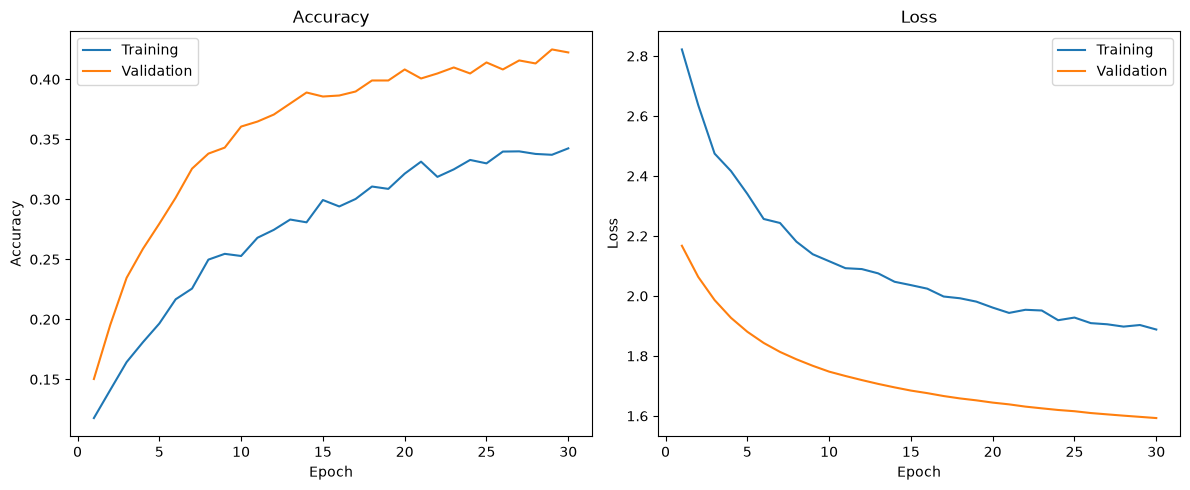

In [109]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 5)
)

axes[0].plot(
    history_df["epoch"],
    history_df["accuracy"],
    label="Training"
)

axes[0].plot(
    history_df["epoch"],
    history_df["val_accuracy"],
    label="Validation"
)

axes[0].set_title(
    "Accuracy"
)

axes[0].set_xlabel(
    "Epoch"
)

axes[0].set_ylabel(
    "Accuracy"
)

axes[0].legend()


axes[1].plot(
    history_df["epoch"],
    history_df["loss"],
    label="Training"
)

axes[1].plot(
    history_df["epoch"],
    history_df["val_loss"],
    label="Validation"
)

axes[1].set_title(
    "Loss"
)

axes[1].set_xlabel(
    "Epoch"
)

axes[1].set_ylabel(
    "Loss"
)

axes[1].legend()

plt.tight_layout()
plt.show()

### Training Behavior
The model demonstrated stable learning behavior throughout the training process. Training accuracy increased from 0.118 during the first epoch to approximately 0.34 by the final epoch, while training loss decreased from 2.82 to approximately 1.89. Validation performance improved concurrently, with validation accuracy increasing from 0.150 to approximately 0.42 and validation loss decreasing from 2.17 to approximately 1.59.

Unlike several of the scratch-trained architectures evaluated in the broader FMA Small study, MobileNetV2 exhibited no obvious signs of overfitting during training. Validation performance improved steadily throughout the experiment, and the validation loss consistently decreased as training progressed. The close agreement between training and validation trends is consistent with the strong generalization behavior observed for MobileNetV2 in the full FMA Small experiments.

### Model Evaluation

In [110]:
# =====================================================
# GENERATE PREDICTIONS
# =====================================================

y_true = []
y_probs = []

for images, labels in test_ds:

    predictions = model.predict(
        images,
        verbose=0
    )

    y_probs.extend(
        predictions
    )

    y_true.extend(
        labels.numpy()
    )

y_true = np.array(
    y_true
)

y_probs = np.array(
    y_probs
)

y_pred = np.argmax(
    y_probs,
    axis=1
)

2026-11-08 15:24:55.515320: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


#### Calculate Metrics

In [111]:
# =====================================================
# CLASSIFICATION METRICS
# =====================================================

test_accuracy = accuracy_score(
    y_true,
    y_pred
)

test_precision = precision_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

test_recall = recall_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

test_f1 = f1_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

print(
    f"Accuracy : {test_accuracy:.4f}"
)

print(
    f"Precision: {test_precision:.4f}"
)

print(
    f"Recall   : {test_recall:.4f}"
)

print(
    f"F1 Score : {test_f1:.4f}"
)

Accuracy : 0.4290
Precision: 0.4211
Recall   : 0.4293
F1 Score : 0.4175


#### Evaluation Summary

In [112]:
# =====================================================
# SUMMARY TABLE
# =====================================================

evaluation_df = pd.DataFrame(
    {
        "Metric": [
            "Accuracy",
            "Precision",
            "Recall",
            "F1 Score"
        ],

        "Value": [

            test_accuracy,

            test_precision,

            test_recall,

            test_f1
        ]
    }
)

evaluation_df

,Metric,Value
0,Accuracy,0.429048
1,Precision,0.421108
2,Recall,0.429267
3,F1 Score,0.417458


The refined MobileNetV2 demonstration achieved a test accuracy of 0.429, with corresponding precision (0.421), recall (0.429), and F1 score (0.417). These values are broadly consistent with the performance range observed throughout the larger FMA Small study and indicate the model successfully learned meaningful genre-discriminative patterns from the training data.

The close agreement between precision, recall, and accuracy suggests performance was relatively balanced across the evaluated genre categories rather than being dominated by a small subset of classes. The slightly lower F1 score (0.417) reflects the continued difficulty of distinguishing certain genre pairs observed throughout the broader FMA Small experiments.

### Classification Report

In [114]:
# =====================================================
# CLASSIFICATION REPORT
# =====================================================

report = classification_report(

    y_true,

    y_pred,

    target_names=CLASS_NAMES,

    output_dict=True,

    zero_division=0
)

classification_report_df = (
    pd.DataFrame(report)
    .transpose()
)

classification_report_df

,precision,recall,f1-score,support
electronic,0.378049,0.416107,0.396166,149.000000
experimental,0.383333,0.306667,0.340741,150.000000
folk,0.440217,0.540000,0.485030,150.000000
hip-hop,0.504808,0.704698,0.588235,149.000000
instrumental,0.519380,0.446667,0.480287,150.000000
international,0.433333,0.346667,0.385185,150.000000
pop,0.317073,0.173333,0.224138,150.000000
rock,0.392670,0.500000,0.439883,150.000000
accuracy,0.429048,0.429048,0.429048,0.429048
macro avg,0.421108,0.429267,0.417458,1198.000000


Genre-level performance varied substantially across the eight FMA Small genres. Hip-Hop achieved the highest recall (0.705) and F1 score (0.588), indicating the model was effective at recognizing recordings from this genre. Folk also achieved relatively strong performance, reaching 0.540 recall and 0.485 F1. These results are consistent with the broader FMA experiments, where Hip-Hop and Folk emerged as two of the most recognizable genres.

Several genres exhibited more moderate performance. Electronic achieved 0.416 recall and 0.396 F1, while Instrumental achieved 0.447 recall and 0.480 F1. Rock achieved 0.500 recall and 0.440 F1, indicating approximately half of the rock recordings in the test set were correctly identified.

Pop remained the most difficult genre to classify. Despite constituting the same number of observations as the other genres (150 test examples), Pop achieved only 0.173 recall and 0.224 F1, the lowest values in the evaluation. This result mirrors the broader FMA Small findings, where Pop consistently exhibited the lowest recall and was heavily represented in the most common confusion pairs.

The variation in recall values, ranging from 0.173 for Pop to 0.705 for Hip-Hop, illustrates why overall accuracy alone provides an incomplete description of model performance. Although the demonstration experiment achieved an overall accuracy of 0.429, the genre-level metrics reveal some genres were recognized reliably while others remained challenging. This pattern motivated the genre-specific analyses performed throughout the larger FMA Small study.

### Genre Performance

In [117]:
# =====================================================
# GENRE PERFORMANCE SUMMARY
# =====================================================

genre_results_df = (
    classification_report_df
    .loc[
        CLASS_NAMES,
        [
            "precision",
            "recall",
            "f1-score"
        ]
    ]
    .reset_index()
    .rename(
        columns={
            "index": "genre",
            "f1-score": "f1"
        }
    )
)

genre_results_df

,genre,precision,recall,f1
0,electronic,0.378049,0.416107,0.396166
1,experimental,0.383333,0.306667,0.340741
2,folk,0.440217,0.540000,0.485030
3,hip-hop,0.504808,0.704698,0.588235
4,instrumental,0.519380,0.446667,0.480287
5,international,0.433333,0.346667,0.385185
6,pop,0.317073,0.173333,0.224138
7,rock,0.392670,0.500000,0.439883


Genre-level performance varied substantially across the evaluated categories. Hip-Hop achieved the strongest overall recall (0.705) and F1 score (0.588), followed by Folk (0.540 recall, 0.485 F1) and Rock (0.500 recall, 0.440 F1). These results indicate the model was able to identify certain genres with reasonable consistency despite achieving only 0.429 overall accuracy on the test set.

Performance was more limited for several genres. Electronic (0.416 recall), Instrumental (0.447 recall), and International (0.347 recall) occupied an intermediate tier of performance, while Experimental achieved 0.307 recall and 0.341 F1. These values suggest the model had greater difficulty learning reliable decision boundaries for some genre categories than others.

Pop remained the most difficult genre to classify, achieving only 0.173 recall and 0.224 F1, the lowest values of any genre in the evaluation. Even though each genre was represented by approximately the same number of evaluation examples (149–150 recordings per genre), the model correctly identified fewer than one in five Pop recordings. This result mirrors the larger FMA Small study, where Pop consistently exhibited the weakest genre-level performance and was heavily represented in the most common confusion pairs.

The spread of recall values, ranging from 0.173 for Pop to 0.705 for Hip-Hop, demonstrates classification performance was not evenly distributed across genres.

### Genre Confusions

In [118]:
# =====================================================
# MOST COMMON CONFUSIONS
# =====================================================

confusion_rows = []

for i, actual in enumerate(CLASS_NAMES):

    for j, predicted in enumerate(CLASS_NAMES):

        if i != j and cm[i, j] > 0:

            confusion_rows.append({

                "actual_genre":
                    actual,

                "predicted_genre":
                    predicted,

                "count":
                    cm[i, j]
            })

confusion_df = (
    pd.DataFrame(
        confusion_rows
    )
    .sort_values(
        "count",
        ascending=False
    )
)

confusion_df.head(10)

,actual_genre,predicted_genre,count
48,pop,rock,36
2,electronic,hip-hop,29
13,experimental,rock,27
38,international,hip-hop,25
44,pop,folk,25
35,international,electronic,24
37,international,folk,23
21,hip-hop,electronic,22
50,rock,experimental,20
47,pop,international,19


The confusion matrix reveals classification errors were concentrated within a relatively small number of recurring genre pairs rather than being distributed evenly across all classes. The single most common confusion occurred when Pop recordings were classified as Rock (36 instances). Pop was also frequently misclassified as Folk (25 instances) and International (19 instances), reinforcing earlier findings Pop represented the most difficult genre in the evaluation.

Several confusion pairs appeared in both directions. Electronic → Hip-Hop (29 instances) and Hip-Hop → Electronic (22 instances) formed one of the strongest bidirectional confusion relationships in the evaluation, suggesting substantial overlap between those genres within the acoustic representation learned by the model. Similar behavior appeared for International → Hip-Hop (25 instances) and International → Electronic (24 instances), indicating several genres share features  the classifier struggled to separate reliably.

Experimental recordings were frequently predicted as Rock (27 instances) and Rock recordings were frequently predicted as Experimental (20 instances), providing evidence of persistent overlap between those categories. Folk and International recordings also exhibited repeated confusion, with International → Folk (23 instances) appearing among the most common error types.

These results demonstrate the model's mistakes were not random. Instead, specific genre boundaries repeatedly generated classification errors, indicating some categories share underlying musical characteristics remain difficult to separate even when a relatively strong architecture such as MobileNetV2 is used. The concentration of errors around Pop, Electronic, Hip-Hop, International, and Experimental recordings suggests genre overlap contributed substantially to the classification challenges observed in this demonstration experiment.

### Error Analysis

Classification errors were concentrated among a relatively small number of recurring genre pairs rather than being distributed evenly across all classes. The most common misclassification occurred when Pop recordings were predicted as Rock, accounting for 36 test examples. Pop recordings were also frequently predicted as Folk (25 examples) and International (19 examples), indicating Pop lacked a clearly separable decision boundary under the evaluated configuration.

Several confusion patterns exhibited near-bidirectional behavior. Electronic recordings were classified as Hip-Hop 29 times, while Hip-Hop recordings were classified as Electronic 22 times. This reciprocal pattern suggests the model identified overlapping acoustic characteristics between the two genres and occasionally struggled to assign a clear categorical distinction.

Additional recurring confusions involved Experimental recordings being classified as Rock (27 examples) and International recordings being classified as Hip-Hop (25 examples), Electronic (24 examples), and Folk (23 examples). These results indicate  some genres overlap with multiple neighboring categories rather than being confused with only a single alternative genre.

The concentration of errors around a limited number of genre pairs is consistent with the findings reported throughout the larger FMA Small study. Genres exhibited lower recall, particularly Pop, also appeared disproportionately often among the most common confusion pairs. Conversely, genres with stronger recall values, such as Hip-Hop and Folk, produced fewer high-frequency misclassification patterns despite remaining involved in several recurring confusion relationships.

Overall, the confusion analysis suggests classification errors were driven primarily by overlap between specific genre boundaries rather than by random prediction failures. Additional listening context improved overall predictive performance, but several genre relationships remained difficult to separate, indicating some ambiguity originates from the structure of the genre taxonomy itself rather than from insufficient audio duration.

## Experimental Results

### Experiment 1: GTZAN
The full summary of the GTZAN dataset experiment results can found within the gtzan_analysis.ipynb notebook at the following github repo:
https://github.com/d-bruning/deep-learning-audio-classification/blob/main/gtzan_analysis.ipynb

### Experiment 2: FMA Small
The full summary of the FMA small dataset experiment results can found within the fma_analysis.ipynb notebook at the following github repo:
https://github.com/d-bruning/deep-learning-audio-classification/

### Notebook MobileNetV2

Figure 5


Figure 7
Table 8
Figure 8
Figure 9
Figure 11
Table 14
Table 15
Table 16